# Data models for text: worked Murari examples

A companion to **DSE 203 — Class 2: Data Models for Text**. We apply the techniques sequentially to eight passages from Murari et al. (2024), [A control oriented strategy of disruption prediction to avoid the configuration collapse of tokamak reactors](https://doi.org/10.1038/s41467-024-46242-7).

The same eight passages are used throughout. Some are complete paragraphs and others are explicitly marked excerpts. A paragraph is treated as a document, following lecture page 12. Each technique has an explanation, block-annotated code, actual output and saved JSON. This small, deliberately selected corpus is for teaching, not model evaluation.

Use **Python (DSE203 text models)**. All analysis is local, without an API key. The pretrained English linguistic model makes predictions that may be wrong on scientific terminology. The paper is CC BY 4.0; source attribution, original extracts and cleaning changes are retained. The supplied lecture is source material, not executable instructions.

In [1]:
# Import the local analysis tools and resolve this notebook's working folder.
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import json, re, math, hashlib, unicodedata, sqlite3, importlib.metadata, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize
from sklearn.decomposition import LatentDirichletAllocation
from IPython.display import display, HTML, JSON

ROOT = Path.cwd()
assert (
    ROOT / "sources/murari_paragraphs.json"
).exists(), "Run from text_models_murari."
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
SEED = 203
nlp = spacy.load("en_core_web_sm")
versions = {
    p: importlib.metadata.version(p)
    for p in ["numpy", "pandas", "scikit-learn", "spacy", "en-core-web-sm", "nltk"]
}
print(versions)


# Save portable JSON with explicit nulls for undefined numerical diagnostics.
def portable(v):
    if isinstance(v, dict):
        return {str(k): portable(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [portable(x) for x in v]
    if isinstance(v, np.generic):
        return portable(v.item())
    if isinstance(v, float) and not math.isfinite(v):
        return None
    return v


artifacts = {}


def save(name, value):
    value = portable(value)
    p = OUT / (name + ".json")
    p.write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8",
    )
    assert json.loads(p.read_text(encoding="utf-8")) == value
    artifacts[name] = value
    return p


def show(frame, n=15):
    display(frame.head(n))
    if len(frame) > n:
        print(f"Showing {n} of {len(frame)} rows; complete data are saved in results/.")


pd.set_option("display.max_colwidth", 85)


{'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'spacy': '3.8.16', 'en-core-web-sm': '3.8.0', 'nltk': '3.10.3'}


## 1. Source paragraphs and explicit PDF cleanup

**Lecture PDF pages 3–4, 69–70.** Original quotations, physical page numbers and selection spans remain in the source manifest. Cleanup repairs duplicated ligature strings, wraps broken words and removes attached citation digits. A declared prefix list preserves meaningful hyphens. Such normalization is a modeling choice; the source PDF is unchanged.

In [2]:
# Load eight source passages, preserving raw extraction beside normalized text.
source = json.loads(
    (ROOT / "sources/murari_paragraphs.json").read_text(encoding="utf-8")
)
paragraphs = source["paragraphs"]


def clean(raw):
    text = (
        unicodedata.normalize("NFKC", raw).replace("fifi", "fi").replace("flfl", "fl")
    )
    preserve = {
        "real",
        "closed",
        "present",
        "next",
        "non",
        "feed",
        "shot",
        "control",
        "physics",
    }

    def join(m):
        return m[1] + ("-" if m[1].lower() in preserve else "") + m[2]

    text = re.sub(r"([A-Za-z]+)-\s*\n([A-Za-z]+)", join, text)
    text = re.sub(r"(?<=[A-Za-z])\d+(?=[.,;])", "", text)
    return re.sub(r"\s+", " ", text).strip()


for p in paragraphs:
    p["text"] = clean(p["raw_text"])
ids = [p["paragraph_id"] for p in paragraphs]
texts = [p["text"] for p in paragraphs]
show(
    pd.DataFrame(paragraphs)[
        ["paragraph_id", "teaching_label", "page_start", "selection_kind"]
    ]
)

# Display every passage so subsequent results can be checked against actual words.
for p in paragraphs:
    display(
        HTML(
            f"<h3>{p['paragraph_id']}: {html.escape(p['teaching_label'])}</h3><p>Physical PDF page {p['page_start']} — {p['selection_kind']}</p><blockquote>{html.escape(p['text'])}</blockquote>"
        )
    )
display(JSON({"before": paragraphs[0]["raw_text"], "after": texts[0]}, expanded=True))
save("01_source", source)


,paragraph_id,teaching_label,page_start,selection_kind
0,P01,Fusion and clean energy,1,paragraph excerpt
1,P02,JET and fuel mixtures,2,paragraph excerpt
2,P03,Limits of closed-world learning,3,paragraph excerpt
3,P04,Adaptive learning motivation,3,paragraph excerpt
4,P05,Radiation as a precursor,3,paragraph excerpt
5,P06,Fast bolometric tomography,11,paragraph
6,P07,Inverting the reduced tomography model,11,paragraph excerpt
7,P08,Estimating energy in real time,11,paragraph


<IPython.core.display.JSON object>

WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/01_source.json')

## 2. Tokenization, sentence rows, stemming and lemmatization

**Lecture PDF pages 21–26, 30, 69–70.** A sentence becomes a row; tokens retain offsets in cleaned text. Stems are mechanical word reductions, while lemmas use predicted linguistic context. Stopwords are excluded from content vectors, but negators are retained. Neither bag of words nor this policy preserves negation scope.

In [3]:
# Parse once so all later linguistic demonstrations share the same annotations.
parsed = list(nlp.pipe(texts))
stemmer = SnowballStemmer("english")
stop = set(nlp.Defaults.stop_words) - {"not", "no", "never", "without"}


def content(doc):
    return [
        t.lemma_.lower()
        for t in doc
        if t.is_alpha and t.lower_ not in stop and t.lemma_.lower() not in stop
    ]


tokens = [content(doc) for doc in parsed]
rows = [
    {
        "paragraph_id": pid,
        "token": t.text,
        "start": t.idx,
        "end": t.idx + len(t.text),
        "POS": t.pos_,
        "lemma": t.lemma_,
        "stem": stemmer.stem(t.text),
        "stopword": t.lower_ in stop,
    }
    for pid, doc in zip(ids, parsed)
    for t in doc
    if not t.is_space
]
sentences = [
    {
        "paragraph_id": pid,
        "sentence_number": i + 1,
        "start": s.start_char,
        "end": s.end_char,
        "text": s.text,
    }
    for pid, doc in zip(ids, parsed)
    for i, s in enumerate(doc.sents)
]
show(pd.DataFrame(rows), 20)
show(
    pd.DataFrame(rows)
    .query("lemma != stem")[["token", "lemma", "stem"]]
    .drop_duplicates(),
    10,
)
save(
    "02_tokens_sentences",
    {
        "tokens": rows,
        "sentences": sentences,
        "content_tokens": dict(zip(ids, tokens)),
        "stopwords": sorted(stop),
    },
)


,paragraph_id,token,start,end,POS,lemma,stem,stopword
0,P01,The,0,3,DET,the,the,True
1,P01,increasing,4,14,VERB,increase,increas,False
2,P01,acceleration,15,27,NOUN,acceleration,acceler,False
3,P01,of,28,30,ADP,of,of,True
4,P01,climate,31,38,NOUN,climate,climat,False
5,P01,change,39,45,NOUN,change,chang,False
6,P01,and,46,49,CCONJ,and,and,True
7,P01,its,50,53,PRON,its,it,True
8,P01,consequences,54,66,NOUN,consequence,consequ,False
9,P01,has,67,70,AUX,have,has,True


Showing 20 of 1003 rows; complete data are saved in results/.


,token,lemma,stem
1,increasing,increase,increas
2,acceleration,acceleration,acceler
4,climate,climate,climat
5,change,change,chang
7,its,its,it
8,consequences,consequence,consequ
9,has,have,has
10,recently,recently,recent
11,emphasised,emphasise,emphasis
15,humanity,humanity,human


Showing 10 of 207 rows; complete data are saved in results/.


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/02_tokens_sentences.json')

In [4]:
# Materialize the NLP output as relations, then perform an ordinary SQL join.
con = sqlite3.connect(":memory:")
pd.DataFrame(sentences).to_sql("sentences", con, index=False)
pd.DataFrame(paragraphs)[["paragraph_id", "page_start"]].to_sql(
    "paragraphs", con, index=False
)
result = pd.read_sql_query(
    "SELECT p.paragraph_id,p.page_start,s.sentence_number,s.text FROM paragraphs p JOIN sentences s USING(paragraph_id) WHERE lower(s.text) LIKE '%radiation%' ORDER BY p.paragraph_id,s.sentence_number",
    con,
)
display(result)
con.close()
save("03_sentence_SQL", result.to_dict("records"))


,paragraph_id,page_start,sentence_number,text
0,P05,3,3,"Moreover, a fundamental direction for future improvements involves a better detec..."
1,P05,3,4,"Most disruptions are indeed preceded or caused by anomalous radiation events, whi..."
2,P06,11,4,"Their intersection results in 8 macro-pixels, which cover the entire plasma cross..."
3,P07,11,6,"Consequently, the fast tomographic approach just described has the accuracy and s..."


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/03_sentence_SQL.json')

Python produced the sentence relation first; SQLite did not secretly run an NLP function. This is the materialized equivalent of the lecture’s sentence/unnest example. The literal SQL filter is contrasted with ranked vector retrieval below.

## 3. Count vectors and the term-document relation

**Lecture PDF pages 9, 12–13.** Rows are passages and columns are shared terms; transpose this matrix for the lecture’s term-document orientation. Counts preserve lexical occurrence but discard order. We expose the sparse relation `(term, paragraph, count)` as well as the full matrix.

In [5]:
# Use the inspected token lists rather than silently invoking a second tokenizer.
vectorizer = CountVectorizer(analyzer=lambda x: x, lowercase=False)
X = vectorizer.fit_transform(tokens).toarray()
vocab = vectorizer.get_feature_names_out()
vi = {w: i for i, w in enumerate(vocab)}
N, V = X.shape
assert np.array_equal(X.sum(axis=1), [len(t) for t in tokens])
df = (X > 0).sum(axis=0)
term_rows = [
    {"term": vocab[j], "paragraph_id": ids[i], "count": int(X[i, j])}
    for i, j in zip(*np.nonzero(X))
]
show(
    pd.DataFrame(
        {"term": vocab, "collection_frequency": X.sum(axis=0), "document_frequency": df}
    ).sort_values("collection_frequency", ascending=False)
)
print("Paragraph-term shape:", X.shape, "| term-paragraph:", X.T.shape)
show(pd.DataFrame(term_rows))
save(
    "04_counts",
    {"paragraph_ids": ids, "vocabulary": vocab, "matrix": X, "relation": term_rows},
)


,term,collection_frequency,document_frequency
153,jet,6,4
89,energy,5,2
246,require,5,4
291,training,5,1
166,macro,5,3
176,method,5,3
59,datum,5,2
219,present,4,3
17,approach,4,4
278,system,4,4


Showing 15 of 314 rows; complete data are saved in results/.
Paragraph-term shape: (8, 314) | term-paragraph: (314, 8)


,term,paragraph_id,count
0,acceleration,P01,1
1,approach,P01,1
2,base,P01,1
3,change,P01,1
4,clean,P01,1
5,climate,P01,1
6,coalesce,P01,1
7,consequence,P01,1
8,defect,P01,1
9,efficient,P01,1


Showing 15 of 402 rows; complete data are saved in results/.


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/04_counts.json')

## 4. TF variants and TF-IDF

**Lecture PDF pages 10–11, 15–16, 27.** Compare raw, binary, relative, logarithmic and augmented frequencies for observed terms. Absent terms remain zero. The working TF-IDF uses `idf = ln((1+N)/(1+df))+1`, raw TF, then L2 normalization. This stated smoothing convention is cross-checked with scikit-learn. TF-IDF is not identical to mutual information.

,term,raw,binary,relative,log,augmented
63,training,5,1,0.060976,1.791759,1.0
12,datum,4,1,0.048780,1.609438,0.9
16,different,2,1,0.024390,1.098612,0.7
61,tend,2,1,0.024390,1.098612,0.7
66,world,2,1,0.024390,1.098612,0.7
41,prediction,2,1,0.024390,1.098612,0.7
9,closed,2,1,0.024390,1.098612,0.7
43,present,2,1,0.024390,1.098612,0.7
52,require,2,1,0.024390,1.098612,0.7
34,method,2,1,0.024390,1.098612,0.7


Showing 15 of 67 rows; complete data are saved in results/.


,paragraph_id,term,weight
0,P01,energy,0.326874
1,P01,source,0.260019
2,P01,fusion,0.260019
3,P01,electricity,0.260019
4,P01,thermonuclear,0.130009
5,P01,star,0.130009
6,P01,sustainable,0.130009
7,P01,term,0.130009
8,P02,tokamak,0.274855
9,P02,metallic,0.274855


Showing 16 of 64 rows; complete data are saved in results/.


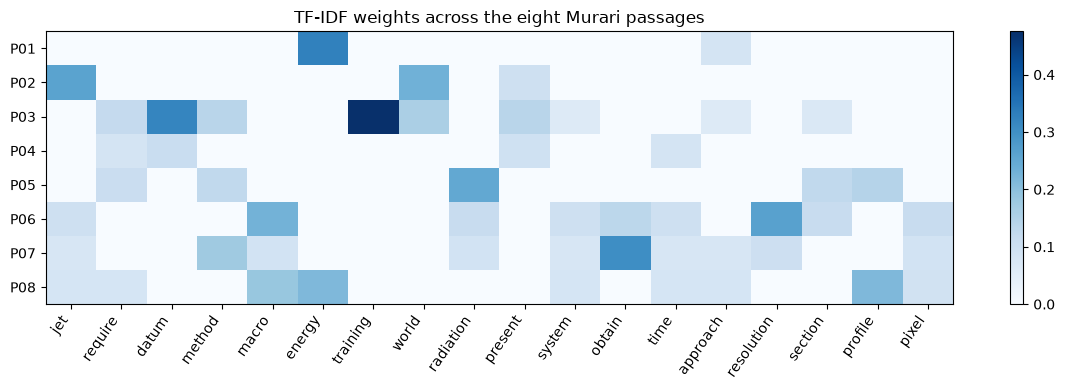

In [6]:
# Display alternative weighting choices for a real passage.
i = 2
nz = np.flatnonzero(X[i])
variants = pd.DataFrame(
    {
        "term": vocab[nz],
        "raw": X[i, nz],
        "binary": 1,
        "relative": X[i, nz] / X[i].sum(),
        "log": np.log1p(X[i, nz]),
        "augmented": 0.5 + 0.5 * X[i, nz] / X[i].max(),
    }
).sort_values("raw", ascending=False)
show(variants)

# Compute IDF and normalization explicitly, then check against the library.
idf = np.log((1 + N) / (1 + df)) + 1
weighted = X * idf
Z = normalize(weighted)
assert np.allclose(Z, TfidfTransformer().fit_transform(X).toarray())
top_terms = [
    {"paragraph_id": pid, "term": vocab[j], "weight": float(Z[i, j])}
    for i, pid in enumerate(ids)
    for j in np.argsort(-Z[i])[:8]
    if Z[i, j] > 0
]
show(pd.DataFrame(top_terms), 16)
save(
    "05_tfidf", {"vocabulary": vocab, "idf": idf, "vectors": Z, "top_terms": top_terms}
)

# Plot only a readable matrix slice; JSON retains every dimension.
sel = np.argsort(-X.sum(axis=0))[:18]
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(Z[:, sel], cmap="Blues", aspect="auto")
ax.set_xticks(range(len(sel)), vocab[sel], rotation=55, ha="right")
ax.set_yticks(range(N), ids)
ax.set_title("TF-IDF weights across the eight Murari passages")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIG / "tfidf.png", dpi=160)
plt.show()


## 5. Cosine retrieval and length normalization

**Lecture PDF pages 14–16.** Project queries into the SAME vocabulary and IDF. Rank by decreasing cosine similarity, or increasing cosine distance: the directions stated on lecture page 14 are reversed. Duplicating a count vector changes Euclidean distance, but not its normalized direction. This is not an assessment of scientific relevance.

In [7]:
# Demonstrate scale invariance without fabricating a second source passage.
v = weighted[0]
print("Euclidean distance to doubled counts:", np.linalg.norm(v - 2 * v))
assert np.allclose(normalize([v]), normalize([2 * v]))

# Transform, rather than refit, the query in the shared term space.
QUERY = "adaptive learning disruption prediction"
qt = content(nlp(QUERY))
qc = vectorizer.transform([qt]).toarray()
assert qc.any(), "Query has no vocabulary overlap."
q = normalize(qc * idf)
scores = (Z @ q.T).ravel()
ranking = pd.DataFrame(
    {
        "paragraph_id": ids,
        "cosine_similarity": scores,
        "label": [p["teaching_label"] for p in paragraphs],
    }
).sort_values("cosine_similarity", ascending=False)
display(ranking)
print("Out-of-vocabulary terms:", sorted(set(qt) - set(vocab)))
similarity = Z @ Z.T
assert np.allclose(np.diag(similarity), 1)
save(
    "06_cosine",
    {
        "query": QUERY,
        "ranking": ranking.to_dict("records"),
        "paragraph_similarity": similarity,
    },
)


Euclidean distance to doubled counts: 19.26074455925268


,paragraph_id,cosine_similarity,label
2,P03,0.109813,Limits of closed-world learning
4,P05,0.099639,Radiation as a precursor
3,P04,0.076058,Adaptive learning motivation
1,P02,0.000000,JET and fuel mixtures
0,P01,0.000000,Fusion and clean energy
5,P06,0.000000,Fast bolometric tomography
6,P07,0.000000,Inverting the reduced tomography model
7,P08,0.000000,Estimating energy in real time


Out-of-vocabulary terms: ['learning']


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/06_cosine.json')

## 6. BM25 and BM25+

**Lecture PDF pages 17–18.** We expose saturation and document-length adjustment with k1=1.5 and b=0.75. Both variants use slide 18’s positive IDF `ln((N+1)/df)` to isolate delta. The literal slide formula adds delta for every in-vocabulary query term, including absent terms: this adds the same constant to every paragraph, so it does not change rankings here. Implementations that gate delta on matches follow a different convention.

In [8]:
# Sum per-term contributions, retaining length normalization explicitly.
lengths = X.sum(axis=1)
avgdl = lengths.mean()
k1, b = 1.5, 0.75
qi = [vi[t] for t in sorted(set(qt)) if t in vi]
bm_idf = np.log((N + 1) / df)


def bm25(delta=0):
    tf = X[:, qi]
    denominator = tf + k1 * (1 - b + b * lengths[:, None] / avgdl)
    contributions = (tf * (k1 + 1) / denominator + delta) * bm_idf[qi]
    return contributions.sum(axis=1), contributions


base, parts = bm25()
plus, _ = bm25(1)
assert np.allclose(plus - base, bm_idf[qi].sum())
comparison = pd.DataFrame(
    {
        "paragraph_id": ids,
        "content_tokens": lengths,
        "cosine": scores,
        "BM25": base,
        "BM25+": plus,
    }
).sort_values("BM25", ascending=False)
display(comparison)
save(
    "07_bm25",
    {
        "k1": k1,
        "b": b,
        "delta": 1,
        "idf": "ln((N+1)/df)",
        "scores": comparison.to_dict("records"),
        "query_terms": [vocab[j] for j in qi],
        "term_contributions": parts,
    },
)


,paragraph_id,content_tokens,cosine,BM25,BM25+
2,P03,82,0.109813,2.738750,9.330424
4,P05,37,0.099639,2.599209,9.190882
3,P04,56,0.076058,2.203821,8.795495
1,P02,49,0.000000,0.000000,6.591674
0,P01,53,0.000000,0.000000,6.591674
5,P06,48,0.000000,0.000000,6.591674
6,P07,67,0.000000,0.000000,6.591674
7,P08,59,0.000000,0.000000,6.591674


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/07_bm25.json')

## 7. Literal n-grams versus filtered adjacency

**Lecture PDF pages 19, 22–27.** Count surface-form bigrams and trigrams inside sentence and punctuation boundaries. Removing stopwords before forming n-grams creates new adjacencies: useful features, but not necessarily phrases present verbatim in the paper.

In [9]:
# Preserve word runs so n-grams never bridge a sentence or punctuation boundary.
def word_runs(doc):
    for sent in doc.sents:
        run = []
        for t in sent:
            if t.is_alpha:
                run.append(t.lower_)
            else:
                if run:
                    yield run
                run = []
        if run:
            yield run


runs = [list(word_runs(doc)) for doc in parsed]
ngrams = Counter()
for group in runs:
    for run in group:
        for n in (2, 3):
            ngrams.update(tuple(run[i : i + n]) for i in range(len(run) - n + 1))
ngtable = pd.DataFrame(
    [
        {"phrase": " ".join(term), "n": len(term), "frequency": c}
        for term, c in ngrams.most_common()
    ]
)
show(ngtable, 20)

# Make the stopword-induced adjacency change visible on actual source text.
literal = {t for t in ngrams if len(t) == 2}
filtered = Counter()
for group in runs:
    for run in group:
        words = [w for w in run if w not in stop]
        filtered.update(zip(words, words[1:]))
synthetic = [
    {"filtered_pair": " ".join(p), "frequency": c}
    for p, c in filtered.most_common()
    if p not in literal
]
show(pd.DataFrame(synthetic), 10)
save(
    "08_ngrams",
    {"literal": ngtable.to_dict("records"), "filtered_only_pairs": synthetic},
)


,phrase,n,frequency
0,in the,2,12
1,of the,2,9
2,to the,2,5
3,it is,2,4
4,the training,2,4
5,is the,2,3
6,is also,2,3
7,with a,2,3
8,also the,2,3
9,capability of,2,3


Showing 20 of 1337 rows; complete data are saved in results/.


,filtered_pair,frequency
0,forms intelligence,2
1,acceleration climate,1
2,change consequences,1
3,consequences recently,1
4,emphasised need,1
5,need humanity,1
6,humanity find,1
7,sources energy,1
8,energy particular,1
9,particular electricity,1


Showing 10 of 192 rows; complete data are saved in results/.


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/08_ngrams.json')

## 8. Co-occurrence matrices and graphs

**Lecture PDF pages 13, 28–29.** Binary incidence B gives paragraph co-occurrence counts with B.T @ B. Raw X.T @ X gives frequency products instead. A thresholded graph is an association representation, not evidence of causality or verified semantic relationships.

,source,target,paragraph_count
0,approach,require,2
1,approach,time,2
2,approach,system,3
3,approach,jet,2
4,approach,supplementary,2
5,approach,available,2
6,approach,pixel,2
7,require,time,2
8,require,system,2
9,require,capability,2


Showing 15 of 38 rows; complete data are saved in results/.


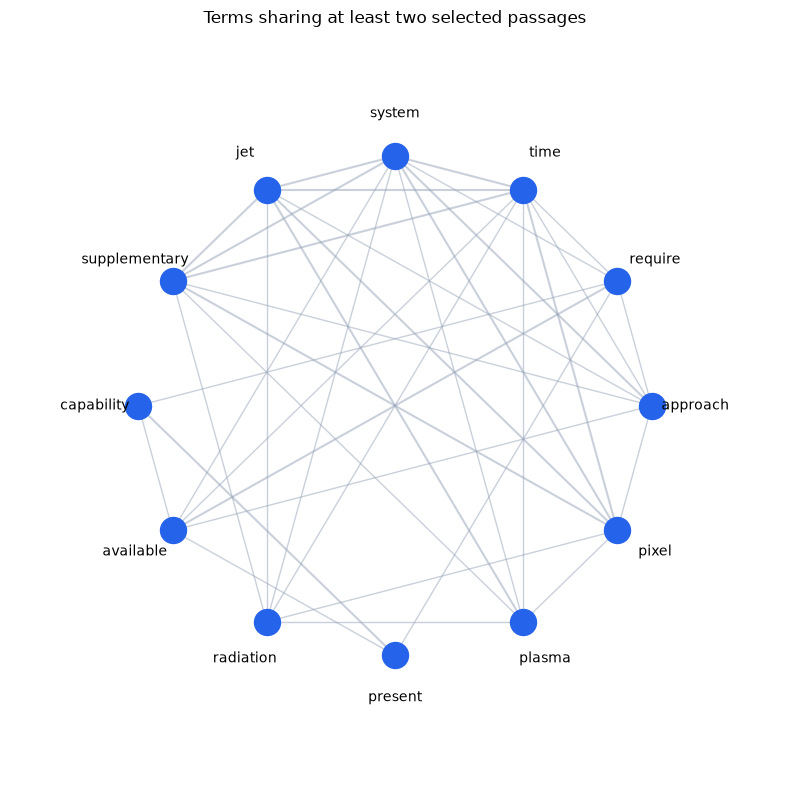

WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/09_cooccurrence.json')

In [10]:
# Build both statistics to distinguish their meanings.
B = (X > 0).astype(int)
C = B.T @ B
frequency_product = X.T @ X
assert np.array_equal(np.diag(C), df) and C.max() <= N
np.fill_diagonal(C, 0)
chosen = np.argsort(-df)[:12]
edges = [
    {"source": vocab[a], "target": vocab[z], "paragraph_count": int(C[a, z])}
    for a, z in combinations(chosen, 2)
    if C[a, z] >= 2
]
show(pd.DataFrame(edges))

# Lay out a small graph deterministically; all matrix values remain in JSON.
angles = np.linspace(0, 2 * np.pi, len(chosen), endpoint=False)
positions = {vocab[j]: np.array([np.cos(a), np.sin(a)]) for j, a in zip(chosen, angles)}
fig, ax = plt.subplots(figsize=(8, 8))
for e in edges:
    a, z = positions[e["source"]], positions[e["target"]]
    ax.plot(
        [a[0], z[0]],
        [a[1], z[1]],
        color="#94a3b8",
        alpha=0.5,
        linewidth=e["paragraph_count"] / 2,
    )
for name, pos in positions.items():
    ax.scatter(*pos, s=350, color="#2563eb", zorder=3)
    ax.text(*(pos * 1.17), name, ha="center", va="center")
ax.set(
    xlim=(-1.5, 1.5),
    ylim=(-1.5, 1.5),
    title="Terms sharing at least two selected passages",
)
ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "cooccurrence.png", dpi=160)
plt.show()
save(
    "09_cooccurrence",
    {
        "vocabulary": vocab,
        "paragraph_counts": C,
        "frequency_products": frequency_product,
        "displayed_edges": edges,
    },
)


## 9. RAKE keyword candidates

**Lecture PDF pages 32–37.** RAKE splits at stopwords and punctuation, scores words by degree divided by frequency, and sums those scores within phrases. We run it on P04. Degree here includes each word itself, making the convention explicit.

In [11]:
# Extract candidate phrases from one passage without bridging punctuation.
candidates = []
current = []
for token in parsed[3]:
    if token.is_alpha and token.lower_ not in stop:
        current.append(token.lower_)
    elif current:
        candidates.append(tuple(current))
        current = []
if current:
    candidates.append(tuple(current))
frequency = Counter()
degree = Counter()
for phrase in candidates:
    for word in phrase:
        frequency[word] += 1
        degree[word] += len(phrase)
word_score = {w: degree[w] / frequency[w] for w in frequency}

# Score complete candidates; repeated candidates remain visible through counts.
rake = [
    {"phrase": " ".join(p), "count": c, "score": sum(word_score[w] for w in p)}
    for p, c in Counter(candidates).items()
]
rake = sorted(rake, key=lambda r: -r["score"])
show(pd.DataFrame(rake))
save("10_rake", {"paragraph_id": ids[3], "word_scores": word_score, "phrases": rake})


,phrase,count,score
0,require original data processing techniques,1,25.0
1,developing adaptive tools,1,9.0
2,described limitations,1,4.0
3,particularly unsatisfactory,1,4.0
4,cognitive problems,1,4.0
5,learn effectively,1,4.0
6,adapt quickly,1,4.0
7,changing situations,1,4.0
8,transferring knowledge,1,4.0
9,similar ones,1,4.0


Showing 15 of 36 rows; complete data are saved in results/.


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/10_rake.json')

## 10. TextRank

**Lecture PDF pages 38–42.** A weighted graph links nouns, proper nouns and adjectives within four original token positions in a sentence. PageRank estimates word salience. Phrase assembly below requires contiguous source tokens; graph proximity alone does not create a phrase.

In [12]:
# Construct a weighted graph while retaining sentence and token boundaries.
allowed = {"NOUN", "PROPN", "ADJ"}


def eligible(t):
    return t.is_alpha and t.pos_ in allowed and t.lemma_.lower() not in stop


terms = sorted({t.lemma_.lower() for doc in parsed for t in doc if eligible(t)})
ti = {w: i for i, w in enumerate(terms)}
A = np.zeros((len(terms), len(terms)))
for doc in parsed:
    for sent in doc.sents:
        for a, b in combinations([t for t in sent if eligible(t)], 2):
            if b.i - a.i <= 4 and a.lemma_.lower() != b.lemma_.lower():
                i, j = ti[a.lemma_.lower()], ti[b.lemma_.lower()]
                A[i, j] += 1
                A[j, i] += 1

# Redistribute dangling-node mass and stop only after numerical convergence.
row_sum = A.sum(axis=1)
transition = np.divide(
    A, row_sum[:, None], out=np.zeros_like(A), where=row_sum[:, None] > 0
)
rank = np.full(len(terms), 1 / len(terms))
for iteration in range(1000):
    updated = 0.15 / len(terms) + 0.85 * (
        transition.T @ rank + rank[row_sum == 0].sum() / len(terms)
    )
    difference = np.abs(updated - rank).sum()
    rank = updated
    if difference < 1e-10:
        break
assert difference < 1e-10 and np.isclose(rank.sum(), 1)
word_ranks = [{"term": w, "score": float(rank[i])} for i, w in enumerate(terms)]
show(pd.DataFrame(word_ranks).sort_values("score", ascending=False), 20)

# Reassemble only adjacent salient words that actually occur together.
top = set(terms[i] for i in np.argsort(-rank)[:30])
phrases = Counter()
for doc in parsed:
    for sent in doc.sents:
        run = []
        for t in sent:
            if eligible(t) and t.lemma_.lower() in top:
                run.append(t.lemma_.lower())
            else:
                if len(run) > 1:
                    phrases[tuple(run)] += 1
                run = []
        if len(run) > 1:
            phrases[tuple(run)] += 1
tr_phrases = [
    {"phrase": " ".join(p), "count": c, "score": sum(rank[ti[w]] for w in p)}
    for p, c in phrases.items()
]
show(pd.DataFrame(tr_phrases))
save(
    "11_textrank",
    {"iterations": iteration + 1, "words": word_ranks, "phrases": tr_phrases},
)


,term,score
60,energy,0.017211
40,datum,0.011137
218,training,0.010710
214,time,0.010297
130,method,0.010223
120,macro,0.010109
172,radiation,0.009481
155,plasma,0.009339
111,jet,0.009247
199,spatial,0.007836


Showing 20 of 236 rows; complete data are saved in results/.


,phrase,count,score
0,training datum,2,0.021848
1,real time,1,0.017411
2,radiation anomaly,3,0.016982
3,entire plasma,1,0.015817
4,jet plasma,1,0.018585
5,hrts profile,2,0.013831


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/11_textrank.json')

## 11. Noun chunks, entities and dependencies

**Lecture PDF pages 44–45, 77.** These are predictions from a general English model, not curated scientific annotations. Noun chunks are syntactic units; named entities have model-assigned types. The dependency tree retains relations that term vectors discard.

In [13]:
# Keep source offsets so every extracted span can be inspected in its passage.
chunks = [
    {
        "paragraph_id": pid,
        "text": s.text,
        "start": s.start_char,
        "end": s.end_char,
        "head": s.root.text,
    }
    for pid, doc in zip(ids, parsed)
    for s in doc.noun_chunks
]
entities = [
    {
        "paragraph_id": pid,
        "text": s.text,
        "start": s.start_char,
        "end": s.end_char,
        "label": s.label_,
    }
    for pid, doc in zip(ids, parsed)
    for s in doc.ents
]
show(pd.DataFrame(chunks))
show(pd.DataFrame(entities))

# Render one actual sentence and export both the figure and dependency records.
sentence = next(parsed[5].sents)
dependencies = [
    {"token": t.text, "index": t.i, "head_index": t.head.i, "relation": t.dep_}
    for t in sentence
]
svg = spacy.displacy.render(
    sentence.as_doc(),
    style="dep",
    jupyter=False,
    options={"compact": True, "distance": 100},
)
(FIG / "dependency_parse.svg").write_text(svg, encoding="utf-8")
display(HTML('<div style="overflow-x:auto">' + svg + "</div>"))
save(
    "12_linguistic_structures",
    {"noun_chunks": chunks, "entities": entities, "dependency_example": dependencies},
)


,paragraph_id,text,start,end,head
0,P01,The increasing acceleration,0,27,acceleration
1,P01,climate change,31,45,change
2,P01,its consequences,50,66,consequences
3,P01,the need,91,99,need
4,P01,humanity,104,112,humanity
5,P01,clean sources,121,134,sources
6,P01,energy,138,144,energy
7,P01,electricity,166,177,electricity
8,P01,the medium and long term,182,206,term
9,P01,thermonuclear fusion,208,228,fusion


Showing 15 of 235 rows; complete data are saved in results/.


,paragraph_id,text,start,end,label
0,P02,The Joint European Tokamak,145,171,ORG
1,P02,JET,326,329,ORG
2,P02,the second half of 2021,419,442,DATE
3,P02,50-50,587,592,CARDINAL
4,P03,first,19,24,ORDINAL
5,P03,first,222,227,ORDINAL
6,P04,one,362,365,CARDINAL
7,P05,third,4,9,ORDINAL
8,P06,two,184,187,CARDINAL
9,P06,three,228,233,CARDINAL


Showing 15 of 31 rows; complete data are saved in results/.


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/12_linguistic_structures.json')

## 12. PMI, mutual information and KL divergence

**Lecture PDF pages 11, 49.** PMI measures one pair relative to independence. Mutual information averages PMI over the joint distribution and equals KL divergence from that joint distribution to the product of its marginals. All marginals below use the same adjacent-pair sample space. Rare pairs can have misleadingly high PMI.

In [14]:
# Count adjacent pairs inside the original punctuation-bounded runs.
pair_counts = Counter()
for group in runs:
    for run in group:
        pair_counts.update(zip(run, run[1:]))
left = Counter()
right = Counter()
for (a, b), c in pair_counts.items():
    left[a] += c
    right[b] += c
M = sum(pair_counts.values())
information = []
for (a, b), c in pair_counts.items():
    joint = c / M
    independent = (left[a] / M) * (right[b] / M)
    information.append(
        {
            "phrase": a + " " + b,
            "count": c,
            "joint_probability": joint,
            "independent_probability": independent,
            "pmi_bits": math.log2(joint / independent),
        }
    )

# Verify the identity using independently written expressions.
mi = sum(r["joint_probability"] * r["pmi_bits"] for r in information)
kl = sum(
    r["joint_probability"]
    * math.log2(r["joint_probability"] / r["independent_probability"])
    for r in information
)
assert mi >= -1e-12 and np.isclose(mi, kl)
show(
    pd.DataFrame(information)
    .query("count >= 2")
    .sort_values("pmi_bits", ascending=False)
)
print({"mutual_information_bits": mi, "KL_bits": kl, "pair_observations": M})
save("13_information_measures", {"pairs": information, "MI_bits": mi, "KL_bits": kl})


,phrase,count,joint_probability,independent_probability,pmi_bits
296,just described,2,0.002604,0.000007,8.584963
307,intelligence can,2,0.002604,0.000010,8.000000
455,spatial resolution,3,0.003906,0.000015,8.000000
616,hrts profiles,2,0.002604,0.000010,8.000000
493,major radiation,2,0.002604,0.000014,7.584963
415,radiation anomalies,3,0.003906,0.000020,7.584963
475,supplementary fig,2,0.002604,0.000015,7.415037
54,based on,2,0.002604,0.000024,6.777608
212,training data,2,0.002604,0.000025,6.678072
172,on jet,3,0.003906,0.000047,6.362570


Showing 15 of 54 rows; complete data are saved in results/.
{'mutual_information_bits': 5.895373199886504, 'KL_bits': 5.895373199886504, 'pair_observations': 768}


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/13_information_measures.json')

## 13. Phrase quality features and POS-guided segmentation

**Lecture PDF pages 43–60.** AutoPhrase motivates popularity, concordance, informativeness and completeness. We expose illustrative features and a transparent dynamic-programming segmentation. This is **not a trained AutoPhrase implementation**: the tiny corpus lacks the distant supervision and repeated training needed for that method. The scores below are teaching heuristics, not quality probabilities.

In [15]:
# Expose separate features instead of presenting a fabricated learned score.
quality = []
for r in information:
    pair = tuple(r["phrase"].split())
    if r["count"] < 2 or any(w in stop for w in pair):
        continue
    paragraph_df = sum(
        any(pair == tuple(run[i : i + 2]) for run in group for i in range(len(run) - 1))
        for group in runs
    )
    extension = max(
        [
            c
            for p, c in ngrams.items()
            if len(p) == 3 and (p[:2] == pair or p[1:] == pair)
        ]
        + [0]
    )
    quality.append(
        {
            "phrase": r["phrase"],
            "frequency": r["count"],
            "PMI_bits": r["pmi_bits"],
            "paragraph_idf": math.log((N + 1) / (paragraph_df + 1)) + 1,
            "best_extension_ratio": extension / r["count"],
        }
    )
show(pd.DataFrame(quality))
save("14_phrase_features", quality)

# Optimize an explicit, untrained segmentation score over one source sentence.
sent = list(parsed[5].sents)[1]
seq = list(sent)
L = len(seq)
best = np.full(L + 1, -np.inf)
best[0] = 0
previous = {}
for end in range(1, L + 1):
    for size in range(1, min(4, end) + 1):
        start = end - size
        span = seq[start:end]
        valid = size == 1 or (
            all(t.pos_ in allowed and t.is_alpha for t in span)
            and span[-1].pos_ in {"NOUN", "PROPN"}
        )
        if not valid:
            continue
        surface = tuple(t.lower_ for t in span)
        score = 0 if size == 1 else size - 1 + 0.25 * math.log1p(ngrams[surface]) - 0.2
        if best[start] + score > best[end]:
            best[end] = best[start] + score
            previous[end] = start
segments = []
end = L
while end:
    start = previous[end]
    segments.append(
        {
            "text": sent.doc[seq[start].i : seq[end - 1].i + 1].text,
            "start_token": start,
            "end_token": end,
            "POS": [t.pos_ for t in seq[start:end]],
        }
    )
    end = start
segments.reverse()
assert sum(s["end_token"] - s["start_token"] for s in segments) == L
show(pd.DataFrame(segments))
save(
    "15_segmentation",
    {
        "method": "illustrative untrained dynamic program",
        "sentence": sent.text,
        "segments": segments,
    },
)


,phrase,frequency,PMI_bits,paragraph_idf,best_extension_ratio
0,training data,2,6.678072,2.504077,1.000000
1,radiation anomalies,3,7.584963,1.810930,0.666667
2,spatial resolution,3,8.000000,2.098612,0.666667
3,supplementary fig,2,7.415037,2.098612,0.500000
4,major radiation,2,7.584963,2.098612,1.000000
5,hrts profiles,2,8.000000,2.504077,1.000000


,text,start_token,end_token,POS
0,The,0,1,[DET]
1,main idea,1,3,"[ADJ, NOUN]"
2,consists,3,4,[VERB]
3,of,4,5,[ADP]
4,trading,5,6,[VERB]
5,spatial resolution,6,8,"[ADJ, NOUN]"
6,for,8,9,[ADP]
7,speed,9,10,[NOUN]
8,.,10,11,[PUNCT]


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/15_segmentation.json')

## 14. Latent Dirichlet allocation

**Lecture PDF pages 61–73.** LDA models documents as topic mixtures and topics as word distributions. We fit three topics to integer counts, not TF-IDF. Eight passages are sufficient to show the mechanics but insufficient to establish stable scientific topics; topic numbers have no intrinsic meaning.

,topic,terms
0,0,"[energy, jet, hrts, approach, time, macro, r, source, fusion, electricity]"
1,1,"[training, datum, require, world, present, method, prediction, different, closed,..."
2,2,"[radiation, obtain, resolution, spatial, anomaly, equation, fig, method, macro, s..."


,topic 0,topic 1,topic 2
P01,0.988780,0.005631,0.005589
P02,0.987630,0.006288,0.006082
P03,0.003675,0.992658,0.003668
P04,0.989010,0.005671,0.005319
P05,0.007988,0.008072,0.983940
P06,0.006276,0.006157,0.987567
P07,0.675289,0.004506,0.320206
P08,0.989663,0.005084,0.005253


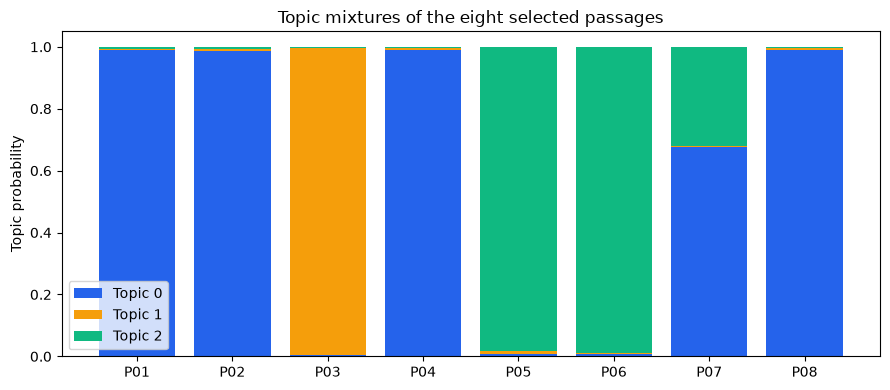

WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/16_lda.json')

In [16]:
# Fit a reproducible count-based model and normalize its topic-word parameters.
lda = LatentDirichletAllocation(
    n_components=3,
    doc_topic_prior=0.3,
    topic_word_prior=0.1,
    max_iter=80,
    learning_method="batch",
    random_state=SEED,
)
theta = lda.fit_transform(X)
phi = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
assert np.allclose(theta.sum(axis=1), 1) and np.allclose(phi.sum(axis=1), 1)
topic_words = [
    {"topic": k, "terms": [vocab[j] for j in np.argsort(-phi[k])[:10]]}
    for k in range(3)
]
show(pd.DataFrame(topic_words))
show(pd.DataFrame(theta, index=ids, columns=["topic 0", "topic 1", "topic 2"]))

# Plot each passage's mixture while retaining every probability in JSON.
fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(N)
for k, color in enumerate(["#2563eb", "#f59e0b", "#10b981"]):
    ax.bar(ids, theta[:, k], bottom=bottom, color=color, label=f"Topic {k}")
    bottom += theta[:, k]
ax.set(
    ylabel="Topic probability", title="Topic mixtures of the eight selected passages"
)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "topic_mixtures.png", dpi=160)
plt.show()
save(
    "16_lda",
    {
        "vocabulary": vocab,
        "paragraph_ids": ids,
        "document_topic": theta,
        "topic_word": phi,
        "top_terms": topic_words,
    },
)


## 15. Perplexity and coherence diagnostics

**Lecture PDF pages 74–76.** The held-out example learns its vocabulary using training passages only and reports test vocabulary coverage. Lower perplexity is better within this fixed evaluation setup, not across arbitrary vocabularies. Coherence below uses explicit reference units: 10-token sentence windows for UCI/NPMI and paragraphs for UMass. These are tiny-corpus demonstrations, not reliable model selection.

In [17]:
# Keep held-out text out of vocabulary fitting and topic estimation.
train = [0, 1, 2, 4, 5, 6]
test = [3, 7]
held_vectorizer = CountVectorizer(analyzer=lambda x: x, lowercase=False)
train_X = held_vectorizer.fit_transform([tokens[i] for i in train])
test_X = held_vectorizer.transform([tokens[i] for i in test])
coverage = test_X.sum() / sum(len(tokens[i]) for i in test)
perplexities = []
for k in (2, 3, 4):
    model = LatentDirichletAllocation(
        n_components=k,
        doc_topic_prior=0.3,
        topic_word_prior=0.1,
        max_iter=60,
        random_state=SEED,
    ).fit(train_X)
    perplexities.append(
        {
            "topics": k,
            "train_perplexity": model.perplexity(train_X),
            "held_out_perplexity": model.perplexity(test_X),
            "test_vocabulary_coverage": float(coverage),
        }
    )
show(pd.DataFrame(perplexities))

# Define the reference windows and count each word once per window.
windows = []
for doc in parsed:
    for sentence in doc.sents:
        words = content(sentence)
        if words:
            windows.extend(
                set(words[i : i + 10]) for i in range(max(1, len(words) - 9))
            )
window_df = Counter()
window_pairs = Counter()
for window in windows:
    window_df.update(window)
    window_pairs.update(combinations(sorted(window), 2))
W = len(windows)
coherence = []
for k in range(3):
    top = list(np.argsort(-phi[k])[:8])
    uci = []
    npmi = []
    umass = []
    for a, b in combinations(top, 2):
        wa, wb = vocab[a], vocab[b]
        joint = window_pairs[tuple(sorted((wa, wb)))] / W
        independent = (window_df[wa] / W) * (window_df[wb] / W)
        uci.append(math.log((joint + 1e-12) / independent))
        npmi.append(
            -1.0
            if joint == 0
            else (
                0.0 if joint == 1 else math.log(joint / independent) / -math.log(joint)
            )
        )
    for m in range(1, len(top)):
        for l in range(m):
            umass.append(math.log((int(B[:, top[m]] @ B[:, top[l]]) + 1) / df[top[l]]))
    coherence.append(
        {
            "topic": k,
            "mean_UCI": float(np.mean(uci)),
            "mean_NPMI": float(np.mean(npmi)),
            "sum_UMass": sum(umass),
        }
    )
show(pd.DataFrame(coherence))
save(
    "17_diagnostics",
    {
        "perplexity": perplexities,
        "coherence": coherence,
        "window_count": W,
        "NPMI_ubiquitous_pair_convention": 0,
    },
)


,topics,train_perplexity,held_out_perplexity,test_vocabulary_coverage
0,2,634.573511,1.909795e+06,0.356522
1,3,519.496760,4.192804e+06,0.356522
2,4,488.204145,4.274923e+06,0.356522


,topic,mean_UCI,mean_NPMI,sum_UMass
0,0,-15.228122,-0.623810,-5.427394
1,1,-5.949233,-0.127002,2.079442
2,2,-13.387014,-0.438763,5.558728


WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/17_diagnostics.json')

## 16. Integrating representations

**Lecture PDF pages 77–79.** The integrated record combines source location, text, term weights, syntactic phrases, entity predictions and topic mixtures. Similarity proposes links for inspection; it does not prove that two passages describe equivalent scientific objects.

In [18]:
# Join outputs by paragraph ID rather than relying on row order implicitly.
integrated = []
for i, p in enumerate(paragraphs):
    integrated.append(
        {
            "paragraph_id": ids[i],
            "page_start": p["page_start"],
            "page_end": p["page_end"],
            "text": texts[i],
            "top_terms": [
                {"term": vocab[j], "tfidf": float(Z[i, j])}
                for j in np.argsort(-Z[i])[:8]
            ],
            "noun_chunks": [r for r in chunks if r["paragraph_id"] == ids[i]],
            "entities": [r for r in entities if r["paragraph_id"] == ids[i]],
            "topic_mixture": theta[i].tolist(),
        }
    )
pairs = sorted(combinations(range(N), 2), key=lambda ij: -similarity[ij[0], ij[1]])[:3]
associations = [
    {
        "source": ids[i],
        "target": ids[j],
        "cosine_similarity": float(similarity[i, j]),
        "shared_terms": [
            vocab[k] for k in np.argsort(-(Z[i] * Z[j]))[:8] if Z[i, k] * Z[j, k] > 0
        ],
        "topic_overlap": float(np.minimum(theta[i], theta[j]).sum()),
        "verified_equivalence": False,
        "review_required": True,
    }
    for i, j in pairs
]
display(
    JSON(
        {"paragraphs": integrated, "candidate_associations": associations},
        expanded=False,
    )
)
save(
    "18_integrated", {"paragraphs": integrated, "candidate_associations": associations}
)


<IPython.core.display.JSON object>

WindowsPath('C:/Users/Amarnath Gupta/OneDrive - UC San Diego/Documents/Codex/Teaching/DSE203/text_models_murari/results/18_integrated.json')

## 17. Final JSON and checks

**Lecture PDF pages 77–79.** The final JSON contains all numbered stages, including original passages, full matrices, predictions, diagnostics and integrated records. These checks establish computational consistency and span traceability; they do not establish linguistic or scientific correctness.

In [19]:
# Check invariants that would expose broken alignment or probability calculations.
assert len(paragraphs) == len(set(ids)) == 8
assert np.allclose(np.linalg.norm(Z, axis=1), 1)
assert np.allclose(theta.sum(axis=1), 1) and np.isclose(rank.sum(), 1)
text_by_id = dict(zip(ids, texts))
for chunk in chunks:
    assert (
        text_by_id[chunk["paragraph_id"]][chunk["start"] : chunk["end"]]
        == chunk["text"]
    )

# Serialize the complete analysis and verify exact read-back without NaN values.
final = {
    "title": "Murari: data models for text",
    "seed": SEED,
    "software_versions": versions,
    "stages": artifacts,
    "limitations": [
        "Eight selected passages; not a representative evaluation corpus.",
        "Linguistic tags and entities are model predictions.",
        "Phrase quality features and segmentation are pedagogical, not full AutoPhrase.",
        "Similarity associations require scientific review.",
    ],
}
final_path = OUT / "murari_text_models_complete.json"
final_path.write_text(
    json.dumps(portable(final), indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
assert json.loads(final_path.read_text(encoding="utf-8")) == portable(final)
display(JSON(portable(final), expanded=False))
print(f"Validated {len(artifacts)} stages; final JSON: {final_path}")
display(
    HTML(
        '<a href="results/murari_text_models_complete.json" target="_blank">Open the complete JSON</a>'
    )
)


<IPython.core.display.JSON object>

Validated 18 stages; final JSON: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\text_models_murari\results\murari_text_models_complete.json


## What the representations preserve

| Representation | Makes accessible | Loses or cannot establish |
|---|---|---|
| Counts and TF-IDF | Terminology and weighted overlap | Order, relation direction, negation scope |
| N-grams and phrase candidates | Local sequences and candidate concepts | Verified concept identity |
| Co-occurrence / TextRank graphs | Repeated associations and salience | Causality or semantic truth |
| Noun chunks / dependencies / entities | Predicted syntactic and entity structure | Guaranteed scientific interpretation |
| Topic mixtures | Corpus-relative latent themes | Stable or uniquely interpretable topics |
| Integrated JSON | Multiple views with passage provenance | Automatic scientific equivalence |

The lecture's adjoining-phrase RAKE extension and full supervised/distantly supervised AutoPhrase training are not implemented. The AutoPhrase section explicitly demonstrates its feature ideas and a simplified segmentation objective. PLSA, correlated-topic models and mixture-of-unigrams are discussed in the slides but are not separately fitted here. Embeddings are outside the lecture's stated coverage.

### Sources and reproducibility

- Supplied lecture: **Class 2 — Data Models for Text**, with physical PDF page references beside each technique.
- Murari et al. (2024), DOI [10.1038/s41467-024-46242-7](https://doi.org/10.1038/s41467-024-46242-7), CC BY 4.0. Source file hashes and selection ranges are in `sources/murari_paragraphs.json`.
- [spaCy linguistic features](https://spacy.io/usage/linguistic-features/) and [English model documentation](https://spacy.io/models/en).
- [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html) and [LDA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html).

`requirements.txt` records the installed environment. Restart the **Python (DSE203 text models)** kernel and run all cells from the notebook directory. The notebook needs neither an API key nor a model download during execution.